# Simulazione Sistema a 2 Corpi

## Librerie

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from Vettori import Vec2D as vec

from matplotlib.animation import FuncAnimation
from matplotlib.patches import Circle

## Costanti utili

Definiamo le costanti necessarie per il programma:

In [2]:
# useremo AU per distanza e Years per tempi
constants = {
    "G_value": 6.6743e-11,      # m^3 kg^-1 s^-2
    "M_sun": 1.9884e30,         # kg
    "M_earth": 5.972e24,        # kg
    "AU_value": 1.49598e11,     # m
    "year2sec": np.pi * 1e7
}
constants["Conv"] = constants["AU_value"]**-3 * constants["year2sec"]**2    # m,s -> AU, Y

params = {
    "N_steps": 5000,
    "Period": 1,            # years
    "N_cycles": 5
}
params["Tau"] = params["N_cycles"] * params["Period"] / params["N_steps"]   # years

# Funzione per simulare

Iniziamo definendo una funzione che si occupi di gestire le condizioni iniziali e di iterare Verlet per gli N-1 steps

## Vettori Posizione e Velocità

Al fine di rendere l'implementazione dell'algoritmo di Verlet più versatile ragioneremo in termini di array  
bidimansionali, di dimensione $N_{body} \times N_{Steps}$.

$$
[\vec{r}] = \left(\begin{array}{cc} 
\vec{r}_1(0) & \vec{r}_1(\Delta t) & \vec{r}_1(2 \Delta t) & ... & \vec{r}_1(N\Delta t)\\
\vec{r}_2(0) & \vec{r}_2(\Delta t) & \vec{r}_2(2 \Delta t) & ... & \vec{r}_2(N\Delta t)
\end{array}\right)
$$ 

$$
[\vec{v}] = \left(\begin{array}{cc} 
\vec{v}_1(0) & \vec{v}_1(\Delta t) & \vec{v}_1(2 \Delta t) & ... & \vec{v}_1(N\Delta t)\\
\vec{v}_2(0) & \vec{v}_2(\Delta t) & \vec{v}_2(2 \Delta t) & ... & \vec{v}_2(N\Delta t)
\end{array}\right)
$$ 

In [3]:
def Simulate(params, constants):

    N_steps = params["N_steps"]
    Tau = params["Tau"]

    M_sun = constants["M_sun"]
    M_earth = constants["M_earth"]
    G_value = constants["G_value"]
    Conv = constants["Conv"]
    masses = np.array([M_sun, M_earth])

    positions = np.full((2, N_steps), fill_value=vec(0, 0))     # array pieni di vettori nulli
    velocities = np.full((2, N_steps), fill_value=vec(0, 0))    # array pieni di vettori nulli

    pos0_S = vec(0, 0)
    pos0_e = vec(1, 0)
    vel0_S = vec(0, 0)
    vel0_e = vec(0, 2*np.pi)        # v = omega * r = 2pi/T * r, r=1AU, T=1y -> v = 2 pi

    positions[:, 0] = pos0_S, pos0_e
    velocities[:, 0] = vel0_S, vel0_e

    for i in range(N_steps - 1):
        old_positions = positions[:, i]
        old_velocities = velocities[:, i]

        new_positions, new_velocities = DoVerlet(old_positions, old_velocities, Tau, G_value, masses, Conv)
        
        positions[:, i+1] = new_positions
        velocities[:, i+1] = new_velocities

    return positions, velocities

## Funzione per Calcolare le Distanze

Al fine di calcolare le accelerazioni ci serve sapere quando sono lontani i due corpi ad ogni istante temporale, per fare ciò creiamo una funzione che prende in imput i vettori posizione dei due corpi ad un certo timestep e restituisce una matrice di distanze.  

Definita la distanza tra i corpi come:

$$
\vec{d_{12}} = \vec{r}_1 - \vec{r}_2
$$
$$
\vec{d_{21}} = \vec{r}_2 - \vec{r}_1
$$

La matrice sarà quindi del tipo:

$$
[\vec{d}] = \left(\begin{array}{cc} 
0 & \vec{d}_{12}\\
\vec{d}_{21} & 0 \\
\end{array}\right)
$$ 

Si nota che:

$$
\vec{d_{21}} = - \vec{d_{12}}
$$

Da cui:

$$
[\vec{d}] = \left(\begin{array}{cc} 
0 & \vec{d}_{12}\\
-\vec{d}_{12} & 0 \\
\end{array}\right)
$$ 

In [4]:
def GetDistances(positions):
    """
    d_ij = p_i - p_j
    """
    N = len(positions)
    dist = np.full((N, N), fill_value=vec(0, 0))

    for i in range(N):
        for j in range(i+1, N):
            dist[i, j] = positions[i] - positions[j]
            dist[j, i] = - dist[i, j]

    return dist

Usando in questo modo il doppio loop accediamo solamente agli elementi al di sopra della diagonale superiore. Qui elementi al di sotto vengono calcolati per simmetria.

## Funzione per Calcolare le Accelerazioni

Utilizziamo un approccio simile per definire una funzione che prenda in input la matrice delle distanze creata dalla funzione precedente e restituisca le accelerazioni totali a cui i due corpi sono soggetti.

Partiamo dalla forma della forza di gravità:

$$
\vec{F}_g = -G \cdot \frac{M \cdot m}{|\vec{d}|^2} \cdot \hat{d}
$$

Dove $\vec{d}$ è il vettore distanza tra i corpi considerati.  

Nel nostro caso le masse dei due corpi sono uguali, quindi possiamo scrivere le due accelerazioni come:

$$
\vec{A}_{12} = -G \cdot \frac{M}{|\vec{d}_{12}|^2} \cdot \hat{d}_{12}
$$
$$
\vec{A}_{21} = -G \cdot \frac{M}{|\vec{d}_{21}|^2} \cdot \hat{d}_{21}
$$

Gli indici indicano il corpo considerato e il corpo a cui è dovuta l'accelerazione: $\vec{A}_{12}$ corrisponde all'accelerazione del corpo 1 per effetto del corpo 2 e così via.  

Da cui la matrice delle accelerazioni:

$$
[\vec{A}] = \left(\begin{array}{cc} 
0 & \vec{A}_{12}\\
\vec{A}_{21} & 0 \\
\end{array}\right)
$$ 

Si nota che:

$$
\vec{A_{21}} = - \vec{A_{12}}
$$

Da cui:

$$
[\vec{A}] = \left(\begin{array}{cc} 
0 & \vec{A}_{12}\\
-\vec{A}_{12} & 0 \\
\end{array}\right)
$$

Dalla trattazione con due soli corpi non è troppo evidente, tuttavia l'accelerazione totale a cui è soggetto il corpo $i-esimo$ non è altro che la somma del valori lungo le righe di questa matrice. Proviamo a vederlo nel caso di N corpi:

$$
[\vec{A}] = \left(\begin{array}{cc} 
0 & \vec{A}_{12} & \vec{A}_{13} &...& \vec{A}_{1N}\\
\vec{A}_{21} & 0 & \vec{A}_{23} &...& \vec{A}_{2N}\\
. & . &  & & .\\
. &  & . & & .\\
. &  &  & . & .\\
\vec{A}_{N1} & \vec{A}_{N2} & \vec{A}_{N3} &...& 0\\
\end{array}\right)
$$ 


Sommando lungo le righe otteniamo:

$$
[\vec{A}] = \left(\begin{array}{cc} 
0 + \vec{A}_{12} + \vec{A}_{13} +...+ \vec{A}_{1N}\\
\vec{A}_{21} + 0 + \vec{A}_{23} +...+ \vec{A}_{2N}\\
. \\
. \\
. \\
\vec{A}_{N1} + \vec{A}_{N2} + \vec{A}_{N3} +...+ 0\\
\end{array}\right)
=
\left(\begin{array}{cc} 
\vec{A}_1\\
\vec{A}_2\\
. \\
. \\
. \\
\vec{A}_N\\
\end{array}\right)
$$


Che risulta essere proprio quello che ci serve!

In [5]:
def GetAcceleration(distances, G_value, masses, Conv):
    """
    F = -g Mm / d**2
    a = -G * m/d**2
    """
    N = len(distances)
    forces = np.full((N, N), fill_value=vec(0, 0))

    for i in range(N):
        for j in range(i+1, N):
            dist = distances[i, j]

            forces[i, j] = -G_value * masses[i] * masses[j] / abs(dist)**2 * Conv * dist.unit()
            forces[j, i] = - forces[i, j]

    accelerations = np.sum(forces, axis=1) / masses
    return accelerations

Il comando "$axis=1$" dice a Numpy di sommare lungo le righe.

## Velocity-Verlet

Tutto quello che ci resta da fare è utilizzare l'algoritmo di Verlet per far evolvere il sistema. La potenza di Numpy sta nel fatto che possiamo fare operazioni tra matrici, per esempio calcoliamo le velocità nel modo:

$$
V_{new} = V_{old} + \frac{1}{2}\left( A_{old} + A_{new}\right) \cdot dt
$$

Che si traduce in:

$$
\left(\begin{array}{cc} 
\vec{v}_{1,new}  \\
\vec{v}_{2,new} \\
\end{array}\right)
=
\left(\begin{array}{cc} 
\vec{v}_{1,old}  \\
\vec{v}_{2,old} \\
\end{array}\right)
+
\frac{1}{2}\left[
\left(\begin{array}{cc} 
\vec{A}_{1,old}  \\
\vec{A}_{2,old} \\
\end{array}\right)
+
\left(\begin{array}{cc} 
\vec{A}_{1,new}  \\
\vec{A}_{2,new} \\
\end{array}\right)
\right] \cdot dt
$$

Per le posizioni vale lo stesso.

In [6]:
def DoVerlet(old_positions, old_velocities, Tau, G_value, masses, Conv):
    """
    a dipende da p
    p_i+1 = p_i + v_i * dt + 1/2 a_i dt**2
    v_i+1 = v_i + 1/2(a_i + a_i+1)*dt
    """
    old_distances = GetDistances(old_positions)
    old_accelerations = GetAcceleration(old_distances, G_value, masses, Conv)

    new_positions = old_positions + old_velocities*Tau + 0.5 * old_accelerations * Tau**2

    new_distances = GetDistances(new_positions)
    new_accelerations = GetAcceleration(new_distances, G_value, masses, Conv)

    new_velocities = old_velocities + 0.5 * (old_accelerations + new_accelerations) * Tau

    return new_positions, new_velocities

In [7]:
positions, velocities = Simulate(params, constants)

## Plotting

Plottiamo le orbite che abbiamo calcolato. Qua l'animazione non va quindi ho messo un grafico normale

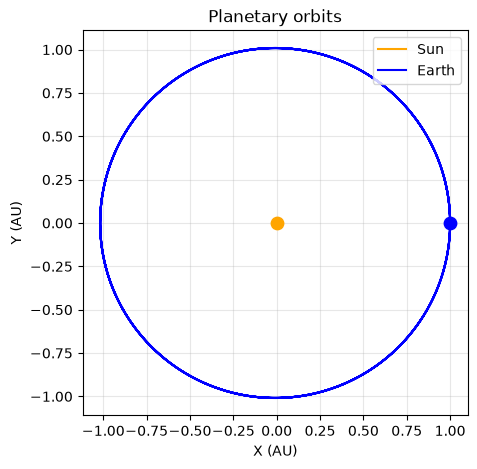

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))

x_sun = [r.x for r in positions[0, :]]
y_sun = [r.y for r in positions[0, :]]
x_earth = [r.x for r in positions[1, :]]
y_earth = [r.y for r in positions[1, :]]


ax.scatter(
    x_sun[0],
    y_sun[0],
    color='orange',
    s=80,
    zorder=5,
)

ax.plot(
    x_sun,
    y_sun,
    color="orange",
    label="Sun",
)

ax.scatter(
    x_earth[0],
    y_earth[0],
    color='blue',
    s=80,
    zorder=5,
)

ax.plot(
    x_earth,
    y_earth,
    color="blue",
    label="Earth",
)

ax.set_xlabel("X (AU)")
ax.set_ylabel("Y (AU)")
ax.set_title("Planetary orbits")
ax.set_aspect("equal")
ax.legend()
ax.grid(alpha=0.3)